# Cookie Cats A/B Testi — 03: İstatistiksel Testler

| Metrik | Rol | Tür | Yöntem |
|---|---|---|---|
| `retention_7` | **Ana metrik** | Oran (0/1) | İki oran z-testi + güven aralığı, bootstrap ile doğrulama |
| `retention_1` | Yardımcı | Oran (0/1) | Aynı |
| `sum_gamerounds` | Koruma (guardrail) | Sayı, çok çarpık | Mann-Whitney U + medyan |

Hipotezler (çift yönlü, α = 0.05): **H0:** gruplar arasında fark yok · **H1:** fark var.

Veri: notebook 02'de temizlenmiş veri (veri hatası olan 1 kayıt çıkarıldı, n = 90.188).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

pd.set_option("display.float_format", "{:.4f}".format)
COLORS = {"gate_30": "#2a78d6", "gate_40": "#eb6834"}
SURFACE, INK, INK2, GRID = "#fcfcfb", "#1f1f1e", "#5f5e5a", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})
FIG = "../figures/"
ALPHA = 0.05

df = pd.read_csv("../data/cookie_cats_clean.csv")
a = df[df["version"] == "gate_30"]   # kontrol
b = df[df["version"] == "gate_40"]   # test
print(len(a), len(b))

44699 45489


## 1. İki oran z-testi

**Mantık:** Her grupta retention bir orandır (dönenler / toplam). H0 doğruysa iki oran aynı popülasyon oranından gelir; z-istatistiği gözlenen farkın, şans eseri beklenen dalgalanmanın kaç standart hatası kadar büyük olduğunu söyler.

Sadece p-değeri değil, şunları birlikte raporluyoruz:
- **Mutlak fark** (puan) ve **göreli fark** (%)
- **Farkın %95 güven aralığı** → "gerçek fark büyük olasılıkla bu aralıkta"
- Her grubun kendi oranı için **Wilson güven aralığı** (oranlar için normal yaklaşımdan daha iyi)

In [2]:
def two_prop_test(metric):
    x = np.array([b[metric].sum(), a[metric].sum()])     # gate_40 - gate_30 sırası
    n = np.array([len(b), len(a)])
    p40, p30 = x / n
    z, p = proportions_ztest(x, n)
    lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="newcomb", compare="diff")
    ci30 = proportion_confint(x[1], n[1], method="wilson")
    ci40 = proportion_confint(x[0], n[0], method="wilson")
    return {
        "metrik": metric, "gate_30": p30, "gate_40": p40,
        "fark_puan": (p40 - p30) * 100, "fark_CI_alt": lo * 100, "fark_CI_ust": hi * 100,
        "goreli_fark_%": (p40 / p30 - 1) * 100, "z": z, "p": p,
        "gate_30_CI": f"[{ci30[0]:.4f}, {ci30[1]:.4f}]", "gate_40_CI": f"[{ci40[0]:.4f}, {ci40[1]:.4f}]",
    }

res = pd.DataFrame([two_prop_test("retention_7"), two_prop_test("retention_1")]).set_index("metrik")
res

,gate_30,gate_40,fark_puan,fark_CI_alt,fark_CI_ust,goreli_fark_%,z,p,gate_30_CI,gate_40_CI
metrik,,,,,,,,,,
retention_7,0.1902,0.1820,-0.8183,-1.3264,-0.3103,-4.3028,-3.1574,0.0016,"[0.1866, 0.1938]","[0.1785, 0.1856]"
retention_1,0.4482,0.4423,-0.5915,-1.2402,0.0572,-1.3198,-1.7871,0.0739,"[0.4436, 0.4528]","[0.4377, 0.4469]"


**Kontrol:** İki oran z-testi, 2×2 tablo üzerindeki ki-kare testiyle (süreklilik düzeltmesi olmadan) matematiksel olarak aynıdır: χ² = z². Mülakatta "z-testi mi ki-kare mi?" sorusunun cevabı: *2 grup ve 0/1 metrik için ikisi aynı sonucu verir.*

In [3]:
for m in ["retention_7", "retention_1"]:
    chi2, p_chi, _, _ = chi2_contingency(pd.crosstab(df["version"], df[m]), correction=False)
    print(f"{m}: chi2 = {chi2:.4f}, z² = {res.loc[m, 'z']**2:.4f}, p_chi2 = {p_chi:.4f}")

retention_7: chi2 = 9.9692, z² = 9.9692, p_chi2 = 0.0016
retention_1: chi2 = 3.1937, z² = 3.1937, p_chi2 = 0.0739


**Yorum:**
- **retention_7:** Fark −0.82 puan, %95 güven aralığı [−1.33, −0.31], p = 0.0016. Kapının hiçbir etkisi olmasaydı, bu büyüklükte bir farkı şans eseri görme olasılığı 10.000'de 16 olurdu. Güven aralığı 0'ı içermiyor: gerçek etki büyük ihtimalle 0.31 ile 1.33 puan arasında bir düşüş. → **İstatistiksel olarak anlamlı.**
- **retention_1:** Fark −0.59 puan, güven aralığı [−1.24, +0.06], p = 0.074. Aralık 0'ı içeriyor; gerçek bir fark olduğunu söylemek için yeterli kanıt yok. Bu "fark yok" demek değil: 1. günde kapıya ulaşan oyuncu az olduğu için etki sulanıyor, notebook 04 ise deneyin bu büyüklükte bir etkiyi yakalayacak kadar hassas olmadığını gösteriyor.
- **p-değeri:** Gerçekte hiç fark olmadığını varsaydığımızda, sadece şans eseri en az gözlemlediğimiz kadar büyük bir fark görme olasılığı. H0'ın doğru olma olasılığı değildir.

## 2. Bootstrap ile doğrulama

**Mantık:** z-testi, örneklem dağılımının normal olduğu varsayımına dayanır. Bootstrap bu varsayımı kullanmaz:
1. Her gruptan, aynı büyüklükte, **iadeli** rastgele örnek çek
2. İki grubun retention farkını hesapla
3. Bunu binlerce kez tekrarla → farkın dağılımını *veriden* elde et
4. Bu dağılımın %2.5 ve %97.5'lik dilimleri = %95 güven aralığı

z-testi ile bootstrap aynı sonuca varıyorsa sonuç yöntem seçimine bağlı değildir → daha güvenilir.

In [4]:
rng = np.random.default_rng(42)
N_BOOT = 5_000
A = a[["retention_1", "retention_7"]].to_numpy()
B = b[["retention_1", "retention_7"]].to_numpy()

diffs = np.empty((N_BOOT, 2))
for i in range(N_BOOT):
    ma = A[rng.integers(0, len(A), len(A))].mean(axis=0)
    mb = B[rng.integers(0, len(B), len(B))].mean(axis=0)
    diffs[i] = mb - ma          # gate_40 - gate_30
boot = pd.DataFrame(diffs * 100, columns=["retention_1", "retention_7"])   # puan cinsinden

boot_summary = pd.DataFrame({
    "bootstrap_CI_alt": boot.quantile(0.025),
    "bootstrap_CI_ust": boot.quantile(0.975),
    "P(gate_40 < gate_30)": (boot < 0).mean(),
})
boot_summary.join(res[["fark_puan", "fark_CI_alt", "fark_CI_ust"]])

,bootstrap_CI_alt,bootstrap_CI_ust,P(gate_40 < gate_30),fark_puan,fark_CI_alt,fark_CI_ust
retention_1,-1.2330,0.0515,0.9624,-0.5915,-1.2402,0.0572
retention_7,-1.3407,-0.3245,0.9994,-0.8183,-1.3264,-0.3103


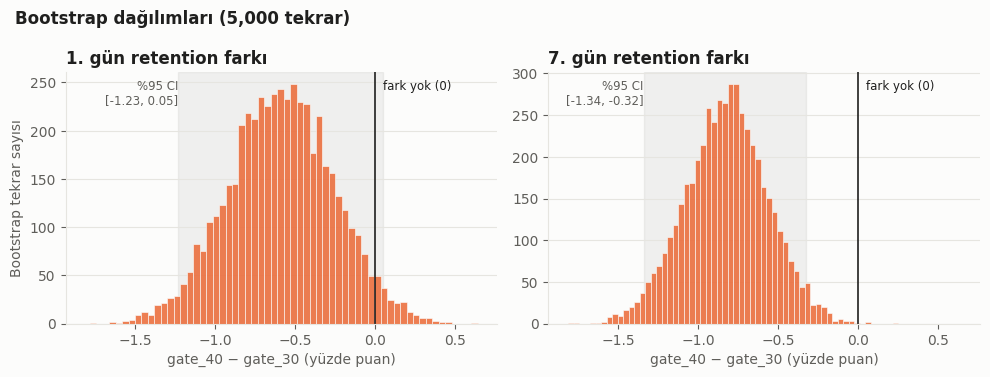

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, m, title in zip(axes, ["retention_1", "retention_7"], ["1. gün retention farkı", "7. gün retention farkı"]):
    lo, hi = boot[m].quantile([0.025, 0.975])
    ax.hist(boot[m], bins=60, color=COLORS["gate_40"], alpha=0.85, edgecolor=SURFACE, linewidth=0.5)
    ax.axvspan(lo, hi, color=INK2, alpha=0.08, zorder=0)
    ax.axvline(0, color=INK, linewidth=1.2)
    ax.text(0.05, ax.get_ylim()[1] * 0.97, "fark yok (0)", fontsize=8.5, color=INK, va="top")
    ax.text(lo, ax.get_ylim()[1] * 0.97, f"%95 CI\n[{lo:.2f}, {hi:.2f}]", fontsize=8.5, color=INK2, va="top", ha="right")
    ax.set_title(title); ax.set_xlabel("gate_40 − gate_30 (yüzde puan)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Bootstrap tekrar sayısı")
fig.suptitle(f"Bootstrap dağılımları ({N_BOOT:,} tekrar)", x=0.02, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG + "05_bootstrap.png", dpi=150, bbox_inches="tight"); plt.show()

**Yorum:** Bootstrap güven aralıkları z-testininkilerle neredeyse aynı (retention_7: [−1.34, −0.32] ve [−1.33, −0.31]). İki farklı yöntem aynı sonucu verdiği için sonuç yöntem seçimine bağlı değil.

`P(gate_40 < gate_30)` sütunu, 5.000 sahte deneyin yüzde kaçında gate_40'ın daha düşük çıktığını gösteriyor: retention_7 için %99.9. Teknik olmayan biri için: *"Deneyi farklı oyuncularla binlerce kez tekrarladığımızı düşündüğümüzde, neredeyse her seferinde gate_40 daha kötü çıkıyor."* (Bu, Bayesçi bir "gate_40'ın daha kötü olma olasılığı" değildir.)

## 3. Round sayısı (koruma metriği): Mann-Whitney U

Dağılım çok çarpık olduğu için ortalamaları karşılaştıran t-testi yerine **sıralara dayalı** Mann-Whitney U kullanıyoruz. Etki büyüklüğü olarak **üstünlük olasılığını** raporluyoruz:

> P(rastgele bir gate_40 oyuncusu, rastgele bir gate_30 oyuncusundan daha çok round oynamış) = U / (n₁·n₂)

0.5 = hiç fark yok.

In [6]:
u, p_mw = mannwhitneyu(b["sum_gamerounds"], a["sum_gamerounds"], alternative="two-sided")
prob_sup = u / (len(a) * len(b))

rounds = pd.DataFrame({
    "medyan": [a["sum_gamerounds"].median(), b["sum_gamerounds"].median()],
    "ortalama": [a["sum_gamerounds"].mean(), b["sum_gamerounds"].mean()],
}, index=["gate_30", "gate_40"])
display(rounds)
print(f"Mann-Whitney U = {u:,.0f}, p = {p_mw:.4f}")
print(f"Üstünlük olasılığı P(gate_40 > gate_30) = {prob_sup:.4f}  (0.5 = fark yok)")

,medyan,ortalama
gate_30,17.0000,51.3421
gate_40,16.0000,51.2988


Mann-Whitney U = 1,009,027,050, p = 0.0509
Üstünlük olasılığı P(gate_40 > gate_30) = 0.4962  (0.5 = fark yok)


**Yorum:** Round sayısında pratik bir fark yok: medyanlar 17 ve 16, üstünlük olasılığı 0.496 (fark yokken beklenen 0.5). p = 0.051 önceden belirlenen 0.05 eşiğinin üstünde; ama asıl önemli olan etki büyüklüğünün önemsiz olması.

Koruma metriği olarak bu sonuç şunu söylüyor: kapının yeri oyuncuların **ne kadar** oynadığını değiştirmemiş, sadece **geri dönüp dönmediklerini** etkilemiş. Retention düşerken oyuncular daha çok oynasaydı, kararı tartmak gerekirdi; burada böyle bir denge yok.

## 4. Çoklu karşılaştırma

Üç test yaptık. Her test %5 yanlış alarm (Tip I hata) riski taşır; test sayısı arttıkça "en az birinde şans eseri anlamlı sonuç" bulma olasılığı da artar: 1 − 0.95³ ≈ %14.

**Bizim durumumuz:** `retention_7` deneyden **önce** ana metrik olarak belirlendi, bu yüzden ana karar düzeltme gerektirmez. Yardımcı metrikler bilgi amaçlıdır. Yine de sonuçların düzeltmeye dayanıklı olup olmadığını gösterelim (Holm yöntemi: Bonferroni'den daha az tutucu, aynı garanti):

In [7]:
tests = pd.DataFrame({
    "test": ["retention_7 (ana)", "retention_1", "sum_gamerounds"],
    "p": [res.loc["retention_7", "p"], res.loc["retention_1", "p"], p_mw],
})
reject, p_holm, _, _ = multipletests(tests["p"], alpha=ALPHA, method="holm")
tests["p_holm"] = p_holm
tests["anlamlı (ham)"] = tests["p"] < ALPHA
tests["anlamlı (Holm)"] = reject
tests

,test,p,p_holm,anlamlı (ham),anlamlı (Holm)
0,retention_7 (ana),0.0016,0.0048,True,True
1,retention_1,0.0739,0.1018,False,False
2,sum_gamerounds,0.0509,0.1018,False,False


## 5. Özet: fark ve güven aralıkları

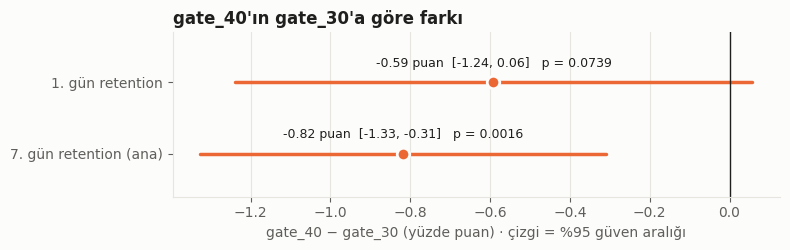

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.6))
rows = ["retention_7", "retention_1"]
labels = ["7. gün retention (ana)", "1. gün retention"]
for i, m in enumerate(rows):
    d, lo, hi = res.loc[m, ["fark_puan", "fark_CI_alt", "fark_CI_ust"]]
    ax.plot([lo, hi], [i, i], color=COLORS["gate_40"], linewidth=2.5, solid_capstyle="round")
    ax.plot(d, i, "o", color=COLORS["gate_40"], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(d, i + 0.22, f"{d:+.2f} puan  [{lo:.2f}, {hi:.2f}]   p = {res.loc[m, 'p']:.4f}",
            ha="center", fontsize=9, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(range(len(rows)), labels); ax.set_ylim(-0.6, len(rows) - 0.3)
ax.set_xlabel("gate_40 − gate_30 (yüzde puan) · çizgi = %95 güven aralığı")
ax.set_title("gate_40'ın gate_30'a göre farkı")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG + "06_fark_ci.png", dpi=150, bbox_inches="tight"); plt.show()

## Test sonuçları özeti

- **Ana metrik (retention_7):** gate_40, gate_30'a göre **0.82 puan** (göreli **%4.3**) daha düşük; %95 CI **[−1.33, −0.31]**, **p = 0.0016**. → İstatistiksel olarak anlamlı; bootstrap ve Holm düzeltmesi (p = 0.005) sonucu destekliyor.
- **retention_1:** 0.59 puan daha düşük, %95 CI [−1.24, +0.06], p = 0.074. → Anlamlı değil; yön retention_7 ile aynı.
- **Round sayısı:** Medyan 17'ye karşı 16, p = 0.051, üstünlük olasılığı 0.496. → Pratikte fark yok.
- **Sınırlamalar:** SRM (p ≈ 0.009), level bilgisi yok, gelir verisi yok.